In [1]:
# =====================================================================
# Olist SQL Setup — runs on BOTH Google Colab and a local machine.
# Run this cell FIRST. It loads the 8 Olist tables into a SQLite
# database and connects the %%sql magic to it. You should not need to
# edit anything unless auto-detection fails (see the two knobs below).
#
# Design notes:
# - We teach SQL with the %%sql cell magic (jupysql), not pd.read_sql().
# - jupysql opens its OWN connection, so the DB must be a real FILE
#   (a :memory: DB would be invisible to it).
# - We use jupysql (the maintained SQL magic). On Colab we install it,
#   because Colab ships the legacy ipython-sql, which (a) can't take a
#   connection by engine variable and (b) renders every result through
#   prettytable.__dict__[style], crashing on modern prettytable with
#   KeyError 'DEFAULT'/'SINGLE_BORDER'. jupysql fixes both.
# - autopandas=True makes every %%sql result a pandas DataFrame, which
#   lets the self-check cells assert on .iloc/.shape directly.
# =====================================================================
import os, glob, sqlite3, tempfile, zipfile
import pandas as pd

# --- Optional knobs (leave blank; only set if auto-detect fails) ------
LOCAL_DATA_DIR = ""   # local run: folder that holds olist_orders_dataset.csv
DRIVE_ZIP_PATH = ""   # Colab: full path to phase-2-python-sql.zip in your Drive
# ---------------------------------------------------------------------

# Detect Colab (google.colab only imports there). Outside Colab — including
# the content-pipeline validator — this falls through to the local branch.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ON_COLAB = True
except ModuleNotFoundError:
    ON_COLAB = False


def _colab_find_zip():
    """Locate phase-2-python-sql.zip in Drive WITHOUT a full recursive scan
    (globbing '/content/drive/MyDrive/**' walks the entire Drive over the
    network and can hang for many minutes). Try explicit paths first, then a
    depth- and count-bounded breadth-first search that prints progress."""
    if DRIVE_ZIP_PATH:
        if os.path.exists(DRIVE_ZIP_PATH):
            return DRIVE_ZIP_PATH
        raise FileNotFoundError(f"DRIVE_ZIP_PATH is set but not found: {DRIVE_ZIP_PATH}")

    target = "phase-2-python-sql.zip"
    # Fast, instant checks of the most likely spots (top of Drive + course folder).
    for cand in (
        f"/content/drive/MyDrive/{target}",
        f"/content/drive/MyDrive/Data Analysis and AI Automation Course Cohort 7/Dataset/{target}",
        f"/content/{target}",
    ):
        if os.path.exists(cand):
            return cand

    # Bounded BFS: depth <= 4, at most ~600 folders, skipping hidden dirs.
    print("Searching your Google Drive for phase-2-python-sql.zip ...")
    root, queue, scanned = "/content/drive/MyDrive", [("/content/drive/MyDrive", 0)], 0
    while queue:
        d, depth = queue.pop(0)
        hit = os.path.join(d, target)
        if os.path.exists(hit):
            return hit
        if depth >= 4:
            continue
        try:
            for e in os.scandir(d):
                if e.is_dir() and not e.name.startswith("."):
                    queue.append((e.path, depth + 1))
        except OSError:
            continue
        scanned += 1
        if scanned % 50 == 0:
            print(f"  ...scanned {scanned} folders")
        if scanned >= 600:
            break

    raise FileNotFoundError(
        "Could not quickly find phase-2-python-sql.zip in your Drive. Put the zip at the "
        "TOP of your Drive (My Drive) and re-run, or set DRIVE_ZIP_PATH at the top of this "
        "cell to its exact path.")


def _find_csv_dir():
    """Return the folder that actually contains olist_orders_dataset.csv."""
    roots = []
    env_dir = os.environ.get("OLIST_DATA_PATH", "")   # set by the pipeline validator
    if env_dir:
        roots.append(env_dir)
    if LOCAL_DATA_DIR:
        roots.append(LOCAL_DATA_DIR)

    if ON_COLAB:
        extract_path = "/content/olist_data"
        # unzip only the first time; reuse the extracted CSVs afterwards
        if not glob.glob(f"{extract_path}/**/olist_orders_dataset.csv", recursive=True):
            zip_path = _colab_find_zip()
            os.makedirs(extract_path, exist_ok=True)
            print(f"Unzipping {os.path.basename(zip_path)} ...")
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(extract_path)
        roots.append(extract_path)
    else:
        # Local: search cwd (recursively) + a few common spots — never the whole
        # home dir (that recursive walk can be very slow). Set LOCAL_DATA_DIR if
        # your CSVs live elsewhere.
        roots += [os.getcwd(),
                  os.path.expanduser("~/Downloads"),
                  os.path.expanduser("~/Desktop"),
                  os.path.expanduser("~/olist")]

    for root in roots:
        if os.path.exists(os.path.join(root, "olist_orders_dataset.csv")):
            return root
        hits = glob.glob(os.path.join(root, "**", "olist_orders_dataset.csv"), recursive=True)
        if hits:
            return os.path.dirname(hits[0])

    raise FileNotFoundError(
        "Olist CSVs not found. Set LOCAL_DATA_DIR (local) or DRIVE_ZIP_PATH (Colab) at "
        "the top of this cell.")


DATA_DIR = _find_csv_dir()
print("Data folder:", DATA_DIR)

# Build a file-based SQLite DB shared by pandas (loading) and jupysql (querying).
DB_PATH = os.environ.get("OLIST_DB_PATH") or (
    "/content/olist.db" if ON_COLAB else os.path.join(tempfile.gettempdir(), "olist.db"))

tables = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "product_category_translation": "product_category_name_translation.csv",
}

conn = sqlite3.connect(DB_PATH)
for table_name, filename in tables.items():
    df = pd.read_csv(os.path.join(DATA_DIR, filename))
    df.to_sql(table_name, conn, if_exists="replace", index=False)
    print(f"Loaded {table_name}: {len(df):,} rows")
conn.close()
print("\nDatabase ready.")

# On Colab, install jupysql so `%load_ext sql` loads it instead of the legacy
# ipython-sql (see header). Off Colab (local / pipeline validator) jupysql is
# already installed, so we skip the install and stay offline-safe.
if ON_COLAB:
    get_ipython().run_line_magic("pip", "install --quiet --upgrade jupysql")

get_ipython().run_line_magic("load_ext", "sql")

# Guard: if the legacy ipython-sql was already loaded earlier THIS session (e.g.
# an older cell ran first), the freshly installed jupysql cannot hot-swap in — a
# runtime restart is the only fix. jupysql exposes sql.connection.ConnectionManager;
# ipython-sql does not. Stop with a clear instruction instead of a later cryptic
# prettytable KeyError.
import sql.connection as _sqlconn
if not hasattr(_sqlconn, "ConnectionManager"):
    raise RuntimeError(
        "Legacy ipython-sql is active, not jupysql. On Colab: Runtime -> Restart session, "
        "then run THIS setup cell first (before any other cell). Locally: "
        "pip install --upgrade jupysql and restart the kernel."
    )

# Connect the %%sql magic to the SAME database file. autopandas=True is REQUIRED
# (see header). We connect with run_line_magic (not a literal `%sql` line) so the
# computed DB_PATH is interpolated correctly. Do NOT set SqlMagic.style.
get_ipython().run_line_magic("config", "SqlMagic.autopandas = True")
get_ipython().run_line_magic("config", "SqlMagic.feedback = 0")
get_ipython().run_line_magic("sql", f"sqlite:///{DB_PATH}")

# Verify (expected row counts — do not alter without re-running against data):
#   orders 99,441 | customers 99,441 | order_items 112,650 | order_payments 103,886
#   order_reviews 99,224 | products 32,951 | sellers 3,095 | product_category_translation 71


Mounted at /content/drive
Searching your Google Drive for phase-2-python-sql.zip ...
Unzipping phase-2-python-sql.zip ...
Data folder: /content/olist_data/phase-2-python-sql
Loaded orders: 99,441 rows
Loaded customers: 99,441 rows
Loaded order_items: 112,650 rows
Loaded order_payments: 103,886 rows
Loaded order_reviews: 99,224 rows
Loaded products: 32,951 rows
Loaded sellers: 3,095 rows
Loaded product_category_translation: 71 rows

Database ready.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.8/192.8 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.6/887.6 kB 46.4 MB/s eta 0:00:00


In [2]:

# =====================================================================
# DATASET CLEANING AND QUALITY CHECKS
# =====================================================================

import pandas as pd

def clean_dataset(table_name, df):
    """Standardize Olist data and report data-quality issues."""

    original_rows = len(df)
    original_columns = len(df.columns)

    # 1. Remove leading/trailing spaces from column names
    df.columns = df.columns.str.strip()

    # 2. Standardize text fields without changing their meaning
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

        # Convert empty strings to missing values
        df[col] = df[col].replace("", pd.NA)

    # 3. Convert known date columns to consistent datetime values
    date_columns = [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "review_creation_date",
        "review_answer_timestamp",
        "shipping_limit_date",
    ]

    for col in date_columns:
        if col in df.columns:
            df[col] = pd.to_datetime(
                df[col], errors="coerce"
            )

    # 4. Standardize Brazilian state codes
    if "customer_state" in df.columns:
        df["customer_state"] = df["customer_state"].str.upper()

    if "seller_state" in df.columns:
        df["seller_state"] = df["seller_state"].str.upper()

    # 5. Ensure review scores are numeric
    if table_name == "order_reviews" and "review_score" in df.columns:
        df["review_score"] = pd.to_numeric(
            df["review_score"], errors="coerce"
        )

        # Flag invalid scores without deleting review records
        invalid_scores = (
            df["review_score"].notna()
            & ~df["review_score"].between(1, 5)
        ).sum()
    else:
        invalid_scores = 0

    # 6. Check exact duplicate rows, but preserve them initially
    # so verified project row counts remain reproducible.
    duplicate_rows = int(df.duplicated().sum())

    # 7. Report missing values
    missing_cells = int(df.isna().sum().sum())

    print(f"\n--- {table_name.upper()} CLEANING REPORT ---")
    print(f"Rows: {original_rows:,} -> {len(df):,}")
    print(f"Columns: {original_columns}")
    print(f"Missing cells: {missing_cells:,}")
    print(f"Exact duplicate rows flagged: {duplicate_rows:,}")

    if table_name == "order_reviews":
        print(f"Invalid review scores flagged: {invalid_scores:,}")

    print("Cleaning complete.")

    return df


In [3]:
import json
try:
    import streamlit as st
except ImportError:
    st = None

# Fallback list of states for testing in the notebook
STATES = ["All", "SP", "RJ", "MG", "ES", "PR", "SC", "RS"]

# Use Streamlit widgets if running in a Streamlit app context, otherwise use static fallback values
if st is not None:
    selected_year  = st.sidebar.selectbox("Year", ["All", "2016", "2017", "2018"])
    selected_state = st.sidebar.multiselect("State", STATES, default=["All"])
else:
    selected_year = "All"
    selected_state = ["All"]

state_json = json.dumps([] if "All" in selected_state else list(selected_state))

def year_params(year):                 # year guard only  -> 2 placeholders
    return (year, year)

def multi_params(multi_json):          # multiselect guard only -> 2 placeholders
    return (multi_json, multi_json)

def year_multi(year, multi_json):      # both guards -> 4 placeholders
    return (year, year, multi_json, multi_json)

# -- Year guard - 2 placeholders
# WHERE (? = 'All' OR strftime('%Y', o.order_purchase_timestamp) = ?)
# -- Multi-select guard - 2 placeholders (the same JSON string twice)
#   AND (? = '[]' OR c.customer_state IN (SELECT value FROM json_each(?)))

**Q1. Headline KPIs**
KPI row · filterable — call with year_params(...); the table below is the All result

In [4]:
get_ipython().run_line_magic("config", 'SqlMagic.named_parameters="enabled"')

# Now we run the cell using the magic as the first executable statement for the SQL parser
get_ipython().run_cell_magic('sql', '', """
SELECT COUNT(DISTINCT o.order_id) AS total_orders,
       COUNT(DISTINCT CASE WHEN o.order_status='delivered' THEN o.order_id END) AS delivered_orders,
       (SELECT ROUND(AVG(CAST(review_score AS REAL)),2) FROM order_reviews) AS avg_review_score,
       SUM(CASE WHEN o.order_status='delivered'
                 AND o.order_delivered_customer_date > o.order_estimated_delivery_date
                THEN 1 ELSE 0 END) AS late_deliveries,
       ROUND(AVG(CASE WHEN o.order_status='delivered' AND o.order_delivered_customer_date IS NOT NULL
                 THEN julianday(o.order_delivered_customer_date)
                    - julianday(o.order_purchase_timestamp) END),2) AS avg_delivery_days
FROM orders o
WHERE (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
""")
# Total Orders	  Delivered Orders	Avg Review Score	Late Deliveries	Avg Delivery Days
# 99,441	          96,478	          4.09	            7,826	          12.56

,total_orders,delivered_orders,avg_review_score,late_deliveries,avg_delivery_days
0,99441,96478,4.09,7826,12.56


**Q2. Review score distribution**
Chart 1 · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard
Verified result (5 rows):

Score	Reviews	Pct
1	11,424	11.50
2	3,151	3.20
3	8,179	8.20
4	19,142	19.30
5	57,328	57.80

In [5]:
%%sql
SELECT CAST(review_score AS INTEGER) AS score,
       COUNT(*)                     AS reviews,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM order_reviews),1) AS pct
FROM order_reviews GROUP BY 1 ORDER BY 1

,score,reviews,pct
0,1,11424,11.5
1,2,3151,3.2
2,3,8179,8.2
3,4,19142,19.3
4,5,57328,57.8


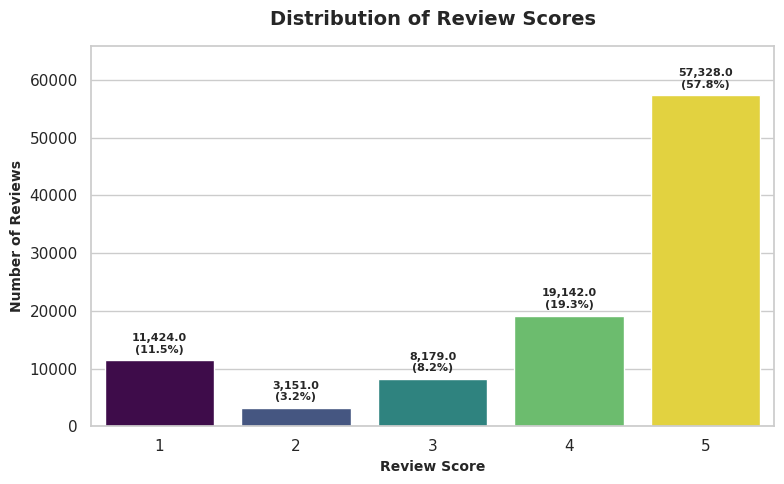

In [12]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch the review distribution data directly from the database
conn = sqlite3.connect(DB_PATH)
query = """
SELECT CAST(review_score AS INTEGER) AS score,
       COUNT(*)                     AS reviews,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM order_reviews),1) AS pct
FROM order_reviews GROUP BY 1 ORDER BY 1
"""
df_reviews = pd.read_sql_query(query, conn)
conn.close()

# Plotting the distribution
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Create a bar plot using Seaborn
ax = sns.barplot(x='score', y='reviews', data=df_reviews, palette='viridis', hue='score', legend=False)

# Add text labels on top of the bars with counts and percentages
for i, bar in enumerate(ax.patches):
    height = bar.get_height()
    pct_val = df_reviews.loc[i, 'pct']
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 1000,
        f"{height:,}\n({pct_val}%)",
        ha='center',
        va='bottom',
        fontsize=8,
        fontweight='bold'
    )

plt.title('Distribution of Review Scores', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Review Score', fontsize=10, fontweight='bold')
plt.ylabel('Number of Reviews', fontsize=10, fontweight='bold')
plt.ylim(0, df_reviews['reviews'].max() * 1.15)  # Add space for the text labels
plt.tight_layout()
plt.show()

**Q3. Monthly average review score**
Chart 2 · filterable — call with year_params(...); the table below is the All result

In [13]:
%%sql
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       COUNT(*) AS reviews,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
GROUP BY month ORDER BY month

,month,reviews,avg_score
0,2016-09,4,1.00
1,2016-10,321,3.57
2,2016-12,1,5.00
3,2017-01,797,4.07
4,2017-02,1776,4.02
5,2017-03,2676,4.07
6,2017-04,2394,4.04
7,2017-05,3703,4.14
8,2017-06,3250,4.15
9,2017-07,4032,4.17


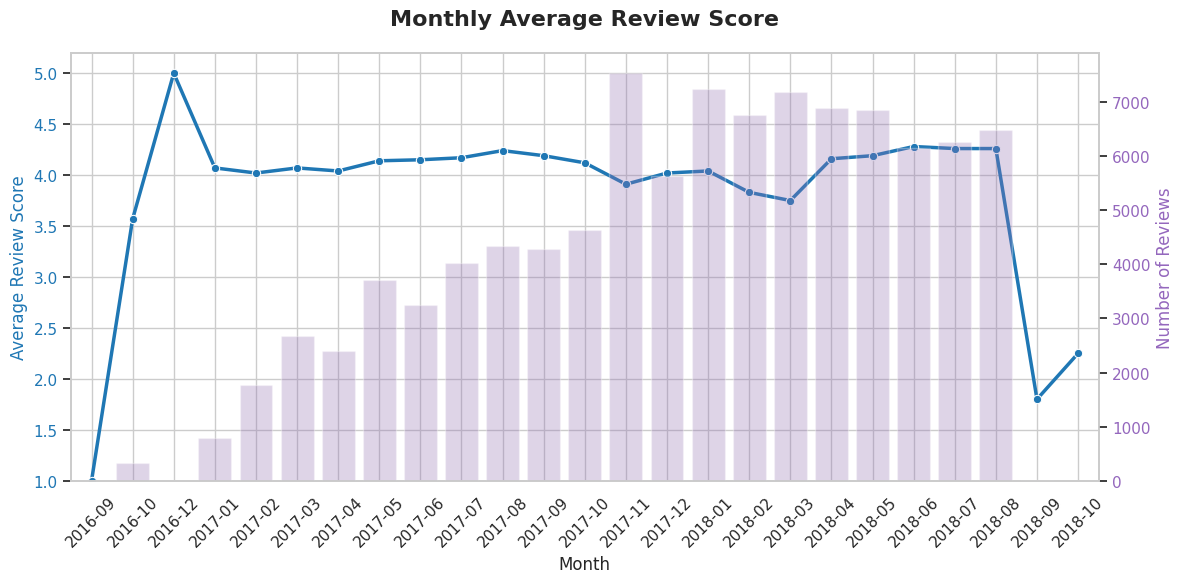

In [15]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch monthly review trends directly from the database using parameter filtering
conn = sqlite3.connect(DB_PATH)
query = """
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       COUNT(*) AS reviews,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE (? = 'All' OR strftime('%Y', o.order_purchase_timestamp) = ?)
GROUP BY month ORDER BY month
"""

# Retrieve data using year_params helper for parameterized filtering
df_monthly = pd.read_sql_query(query, conn, params=year_params(selected_year))
conn.close()

# Plotting the dual-axis trend
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(12, 6))

# Primary axis: Average Review Score
color_score = '#1f77b4'
sns.lineplot(
    x='month',
    y='avg_score',
    data=df_monthly,
    color=color_score,
    marker='o',
    linewidth=2.5,
    ax=ax1
)
ax1.set_title('Monthly Average Review Score', fontsize=16, pad=20, fontweight='bold')
ax1.set_xlabel('Month', fontsize=12)
ax1.set_ylabel('Average Review Score', color=color_score, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_score)
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(1, 5.2)

# Secondary axis: Review Volume
ax2 = ax1.twinx()
color_volume = '#9467bd'
sns.barplot(
    x='month',
    y='reviews',
    data=df_monthly,
    color=color_volume,
    alpha=0.3,
    ax=ax2
)
ax2.set_ylabel('Number of Reviews', color=color_volume, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_volume)
ax2.grid(False)

plt.tight_layout()
plt.show()

**Q4. Average review score by state (top 10 by orders)**
Chart 3 · filterable — call with multi_params(...); the table below is the All result

In [18]:
%%sql
SELECT c.customer_state AS state,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_reviews r ON o.order_id = r.order_id
WHERE (:state_json = '[]' OR c.customer_state IN (SELECT value FROM json_each(:state_json)))
GROUP BY c.customer_state 
ORDER BY orders DESC 
LIMIT 10

,state,orders,avg_score
0,SP,41472,4.17
1,RJ,12687,3.87
2,MG,11554,4.14
3,RS,5443,4.13
4,PR,5019,4.18
5,SC,3609,4.07
6,BA,3340,3.86
7,DF,2128,4.06
8,GO,2007,4.04
9,ES,2006,4.04


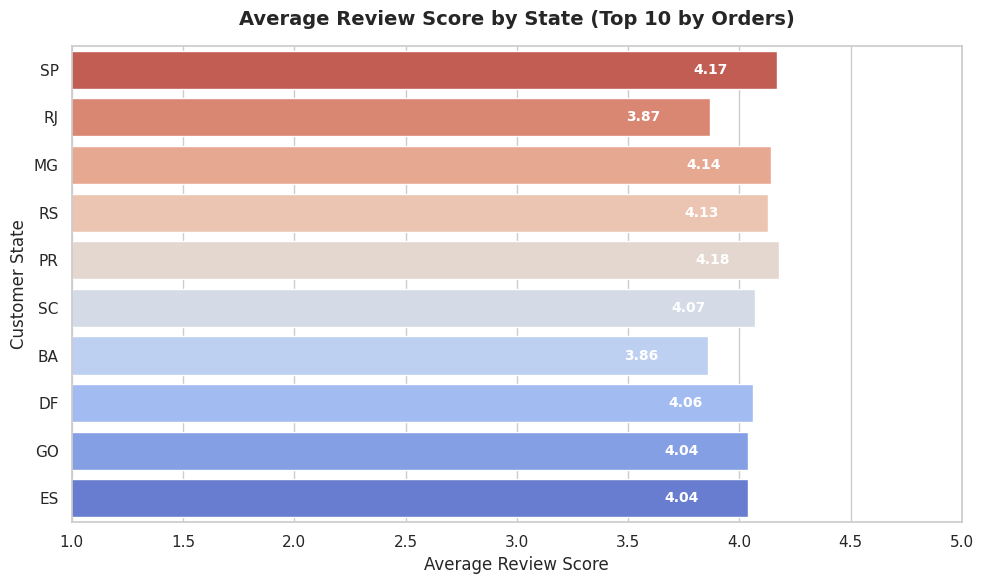

In [19]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch average review score by state (top 10 by orders) directly from the database using parameter filtering
conn = sqlite3.connect(DB_PATH)
query = """
SELECT c.customer_state AS state,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_reviews r  ON o.order_id  = r.order_id
WHERE (? = '[]' OR c.customer_state IN (SELECT value FROM json_each(?)))
GROUP BY state ORDER BY orders DESC LIMIT 10
"""

# Retrieve data using multi_params helper for parameterized filtering
df_state = pd.read_sql_query(query, conn, params=multi_params(state_json))
conn.close()

# Plotting the horizontal bar chart
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create bar plot
ax = sns.barplot(
    x='avg_score',
    y='state',
    data=df_state,
    palette='coolwarm_r',
    hue='state',
    legend=False
)

# Customize the chart
plt.title('Average Review Score by State (Top 10 by Orders)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Average Review Score', fontsize=12)
plt.ylabel('Customer State', fontsize=12)
plt.xlim(1, 5)

# Add exact value labels inside or next to each bar
for bar in ax.patches:
    width = bar.get_width()
    ax.text(
        width - 0.3 if width > 2 else width + 0.1,
        bar.get_y() + bar.get_height() / 2.0,
        f"{width:.2f}",
        ha='center' if width > 2 else 'left',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='white' if width > 2 else 'black'
    )

plt.tight_layout()
plt.show()

**Q5. On-time vs late delivery by state (top 5)**
Chart 4 · filterable — call with multi_params(...); the table below is the All  -- result not verified

In [21]:
%%sql
SELECT c.customer_state AS state,
       COUNT(*) AS delivered,
       SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date 
                THEN 1 ELSE 0 END) AS late,
       ROUND(100.0 * SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date 
                              THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_state
ORDER BY delivered DESC
LIMIT 5

,state,delivered,late,late_pct
0,SP,40501,2387,5.89
1,RJ,12350,1664,13.47
2,MG,11354,637,5.61
3,RS,5345,382,7.15
4,PR,4923,246,5.00


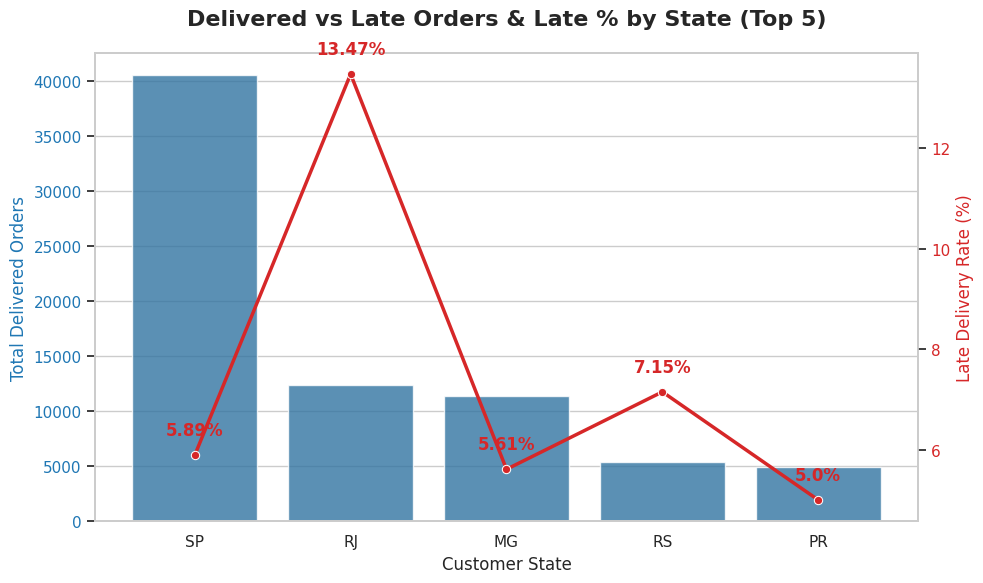

In [22]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch the top 5 states data dynamically from the database using parameter filtering
conn = sqlite3.connect(DB_PATH)
query = """
SELECT c.customer_state AS state,
       COUNT(*) AS delivered,
       SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date 
                THEN 1 ELSE 0 END) AS late,
       ROUND(100.0 * SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date 
                              THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND (? = '[]' OR c.customer_state IN (SELECT value FROM json_each(?)))
GROUP BY c.customer_state
ORDER BY delivered DESC
LIMIT 5
"""

# Retrieve data using multi_params helper for parameterized filtering
df_top5 = pd.read_sql_query(query, conn, params=multi_params(state_json))
conn.close()

# Set style and figure size
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

# Create a primary bar chart for total delivered orders
color_delivered = '#1f77b4'
sns.barplot(
    x='state',
    y='delivered',
    data=df_top5,
    color=color_delivered,
    ax=ax1,
    alpha=0.8
)
ax1.set_title('Delivered vs Late Orders & Late % by State (Top 5)', fontsize=16, pad=20, fontweight='bold')
ax1.set_xlabel('Customer State', fontsize=12)
ax1.set_ylabel('Total Delivered Orders', color=color_delivered, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_delivered)

# Instantiate a second axes that shares the same x-axis for the Late % line
ax2 = ax1.twinx()
color_pct = '#d62728'
sns.lineplot(
    x='state',
    y='late_pct',
    data=df_top5,
    color=color_pct,
    marker='o',
    linewidth=2.5,
    ax=ax2
)
ax2.set_ylabel('Late Delivery Rate (%)', color=color_pct, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_pct)
ax2.grid(False)  # Avoid overlapping grid lines

# Add data labels for the percentages
for x_val, y_val in zip(range(len(df_top5)), df_top5['late_pct']):
    ax2.text(x_val, y_val + 0.4, f"{y_val}%", color=color_pct, ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Q6. Delivery punctuality vs satisfaction**
Advanced feature · filterable — call with multi_params(...); the table below is the All result.
--- result not verified

In [24]:
%%sql
SELECT 
    CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
         THEN 'Late' ELSE 'On Time' END AS delivery_status,
    COUNT(DISTINCT o.order_id) AS orders,
    ROUND(AVG(CAST(r.review_score AS REAL)), 2) AS avg_score,
    ROUND(AVG(julianday(o.order_delivered_customer_date)
            - julianday(o.order_purchase_timestamp)), 2) AS avg_delivery_days
FROM orders o
JOIN order_reviews r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY 1 
ORDER BY orders DESC;

,delivery_status,orders,avg_score,avg_delivery_days
0,On Time,88171,4.29,10.88
1,Late,7661,2.57,31.39


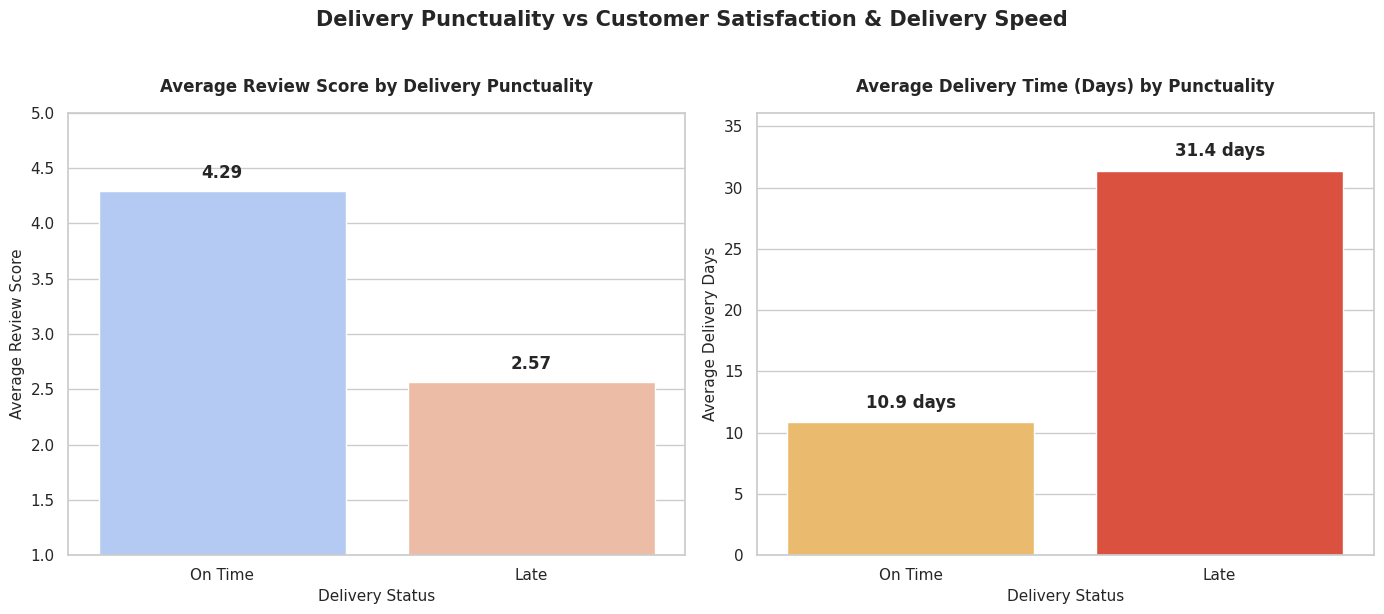

In [25]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch delivery satisfaction and speed metrics from the database
conn = sqlite3.connect(DB_PATH)
query = """
SELECT 
    CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
         THEN 'Late' ELSE 'On Time' END AS delivery_status,
    COUNT(DISTINCT o.order_id) AS orders,
    ROUND(AVG(CAST(r.review_score AS REAL)), 2) AS avg_score,
    ROUND(AVG(julianday(o.order_delivered_customer_date)
            - julianday(o.order_purchase_timestamp)), 2) AS avg_delivery_days
FROM orders o
JOIN order_reviews r ON o.order_id = r.order_id
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND (? = '[]' OR c.customer_state IN (SELECT value FROM json_each(?)))
GROUP BY 1 
ORDER BY orders DESC;
"""

df_punctuality = pd.read_sql_query(query, conn, params=multi_params(state_json))
conn.close()

# Plotting the results
sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Left Chart: Average Review Score
sns.barplot(
    x='delivery_status',
    y='avg_score',
    data=df_punctuality,
    palette='coolwarm',
    hue='delivery_status',
    legend=False,
    ax=ax1
)
ax1.set_title('Average Review Score by Delivery Punctuality', fontsize=12, fontweight='bold', pad=15)
ax1.set_xlabel('Delivery Status', fontsize=11)
ax1.set_ylabel('Average Review Score', fontsize=11)
ax1.set_ylim(1, 5)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.1),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# Right Chart: Average Delivery Days
sns.barplot(
    x='delivery_status',
    y='avg_delivery_days',
    data=df_punctuality,
    palette='YlOrRd',
    hue='delivery_status',
    legend=False,
    ax=ax2
)
ax2.set_title('Average Delivery Time (Days) by Punctuality', fontsize=12, fontweight='bold', pad=15)
ax2.set_xlabel('Delivery Status', fontsize=11)
ax2.set_ylabel('Average Delivery Days', fontsize=11)
ax2.set_ylim(0, df_punctuality['avg_delivery_days'].max() * 1.15)
for p in ax2.patches:
    ax2.annotate(f"{p.get_height():.1f} days", (p.get_x() + p.get_width() / 2., p.get_height() + 1),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold')

plt.suptitle('Delivery Punctuality vs Customer Satisfaction & Delivery Speed', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Q7. Average days late when late**
Diagnostic · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard

In [26]:
%%sql
SELECT COUNT(*) AS late_orders,
       ROUND(AVG(julianday(order_delivered_customer_date)
               - julianday(order_estimated_delivery_date)),2) AS avg_days_late,
       ROUND(MAX(julianday(order_delivered_customer_date)
               - julianday(order_estimated_delivery_date)),0) AS worst_days_late
FROM orders
WHERE order_status='delivered'
  AND order_delivered_customer_date > order_estimated_delivery_date

,late_orders,avg_days_late,worst_days_late
0,7826,9.55,189.0


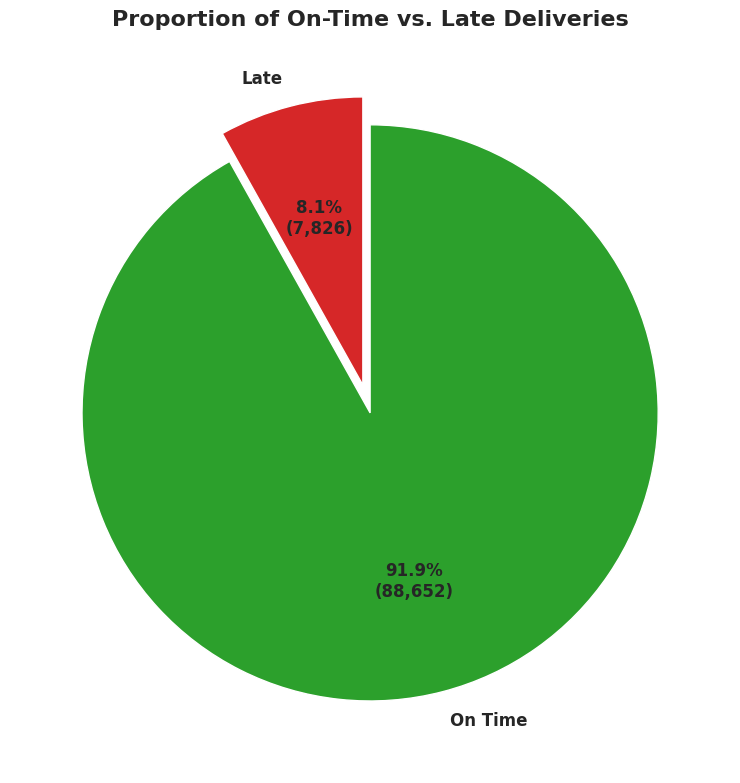

In [32]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch total count of on-time vs late delivered orders
conn = sqlite3.connect(DB_PATH)
query = """
SELECT
    CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
         THEN 'Late' ELSE 'On Time' END AS delivery_status,
    COUNT(*) AS orders
FROM orders o
WHERE o.order_status = 'delivered'
GROUP BY 1;
"""
df_delivery_pie = pd.read_sql_query(query, conn)
conn.close()

# Map colors explicitly based on category to ensure correctness
# df_delivery_pie has 'Late' and 'On Time' rows.
color_map = {'On Time': '#2ca02c', 'Late': '#d62728'}  # Green for On Time, Red for Late
colors = [color_map[status] for status in df_delivery_pie['delivery_status']]

# Plotting
plt.figure(figsize=(8, 8))

plt.pie(
    df_delivery_pie['orders'],
    labels=df_delivery_pie['delivery_status'],
    autopct=lambda pct: f"{pct:.1f}%\n({int(pct/100.*sum(df_delivery_pie['orders'])):,})",
    startangle=90,
    colors=colors,
    explode=[0.1 if status == 'Late' else 0 for status in df_delivery_pie['delivery_status']],
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

plt.title('Proportion of On-Time vs. Late Deliveries', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

**Q8. Review volume by month**
Chart support · filterable — call with year_params(...); the table below is the All result

In [29]:
%%sql
SELECT strftime('%Y', o.order_purchase_timestamp) AS year,
       COUNT(*) AS reviews
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
GROUP BY year ORDER BY year

,year,reviews
0,2016,326
1,2017,45044
2,2018,53854


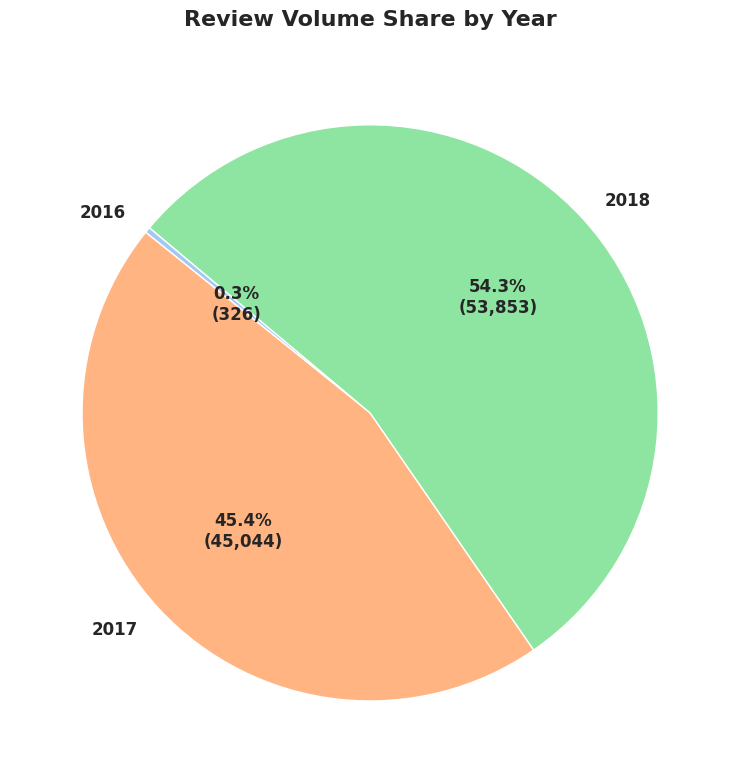

In [31]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch review volume data dynamically using parameter filtering
conn = sqlite3.connect(DB_PATH)
query = """
SELECT strftime('%Y', o.order_purchase_timestamp) AS year,
       COUNT(*) AS reviews
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE (? = 'All' OR strftime('%Y', o.order_purchase_timestamp) = ?)
GROUP BY year ORDER BY year
"""

df_year_reviews = pd.read_sql_query(query, conn, params=year_params(selected_year))
conn.close()

# Plotting the annual review volume as a pie chart
plt.figure(figsize=(8, 8))
colors = sns.color_palette('pastel')[0:len(df_year_reviews)]

plt.pie(
    df_year_reviews['reviews'],
    labels=df_year_reviews['year'],
    autopct=lambda pct: f"{pct:.1f}%\n({int(pct/100.*sum(df_year_reviews['reviews'])):,})" if pct > 0 else '',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

plt.title('Review Volume Share by Year', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

**Q9. Satisfaction by delivery-time bucket**:
Analysis · filterable — call with year_params(...); the table below is the All result

In [27]:
%%sql
SELECT CASE
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 5  THEN '0-5 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 10 THEN '6-10 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 20 THEN '11-20 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 30 THEN '21-30 days'
         ELSE '30+ days' END AS delivery_bucket,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE o.order_status='delivered'
  AND (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
GROUP BY 1 ORDER BY 1

,delivery_bucket,orders,avg_score
0,0-5 days,13374,4.45
1,11-20 days,35547,4.22
2,21-30 days,9588,3.69
3,30+ days,4438,2.26
4,6-10 days,32885,4.36


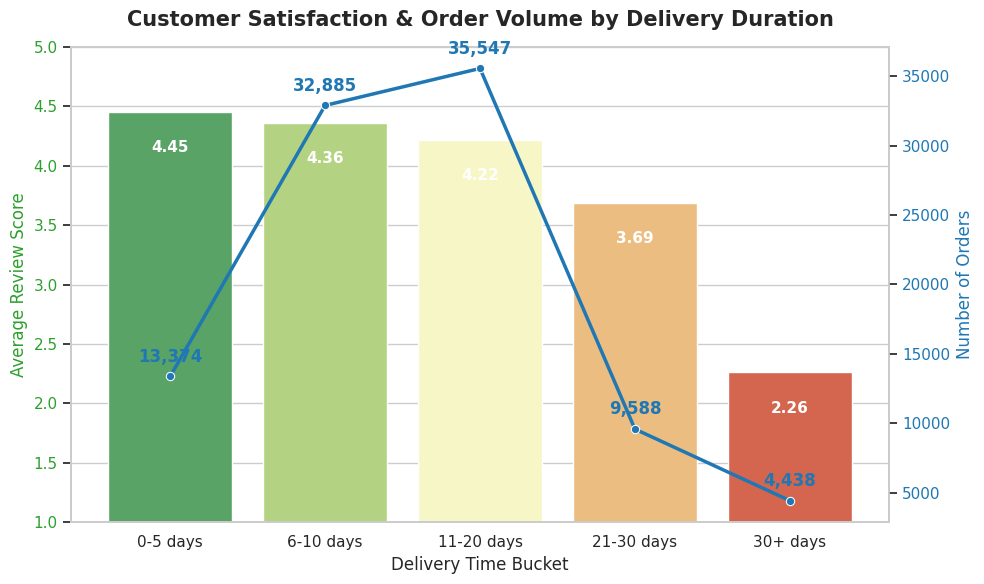

In [28]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fetch satisfaction by delivery-time bucket dynamically from the database using parameter filtering
conn = sqlite3.connect(DB_PATH)
query = """
SELECT CASE
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 5  THEN '0-5 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 10 THEN '6-10 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 20 THEN '11-20 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 30 THEN '21-30 days'
         ELSE '30+ days' END AS delivery_bucket,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE o.order_status='delivered'
  AND (? = 'All' OR strftime('%Y', o.order_purchase_timestamp) = ?)
GROUP BY 1 ORDER BY 1
"""

df_buckets = pd.read_sql_query(query, conn, params=year_params(selected_year))
conn.close()

# Define logical sorting order for the delivery buckets
bucket_order = ['0-5 days', '6-10 days', '11-20 days', '21-30 days', '30+ days']
df_buckets['delivery_bucket'] = pd.Categorical(df_buckets['delivery_bucket'], categories=bucket_order, ordered=True)
df_buckets = df_buckets.sort_values('delivery_bucket').reset_index(drop=True)

# Plotting
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

# Primary Axis: Bar plot for Average Review Score
color_score = '#2ca02c'
ax = sns.barplot(
    x='delivery_bucket',
    y='avg_score',
    data=df_buckets,
    palette='RdYlGn_r',
    hue='delivery_bucket',
    legend=False,
    ax=ax1
)
ax1.set_title('Customer Satisfaction & Order Volume by Delivery Duration', fontsize=15, fontweight='bold', pad=15)
ax1.set_xlabel('Delivery Time Bucket', fontsize=12)
ax1.set_ylabel('Average Review Score', color=color_score, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_score)
ax1.set_ylim(1, 5)

# Add exact value labels inside or next to each bar
for bar in ax.patches:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        height - 0.3 if height > 2 else height + 0.1,
        f"{height:.2f}",
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        color='white' if height > 2 else 'black'
    )

# Secondary Axis: Line plot for Order Volume
ax2 = ax1.twinx()
color_orders = '#1f77b4'
sns.lineplot(
    x='delivery_bucket',
    y='orders',
    data=df_buckets,
    color=color_orders,
    marker='o',
    linewidth=2.5,
    ax=ax2
)
ax2.set_ylabel('Number of Orders', color=color_orders, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_orders)
ax2.grid(False)

# Annotate order volumes on the line
for x_val, y_val in enumerate(df_buckets['orders']):
    ax2.text(x_val, y_val + (df_buckets['orders'].max() * 0.03), f"{y_val:,}", color=color_orders, ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Q10. Reviews fan-out diagnostic**

Data quality · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard

In [28]:
%%sql
SELECT COUNT(*) AS review_rows, COUNT(DISTINCT order_id) AS distinct_orders,
       COUNT(*) - COUNT(DISTINCT order_id) AS duplicate_rows
FROM order_reviews

,review_rows,distinct_orders,duplicate_rows
0,99224,98673,551


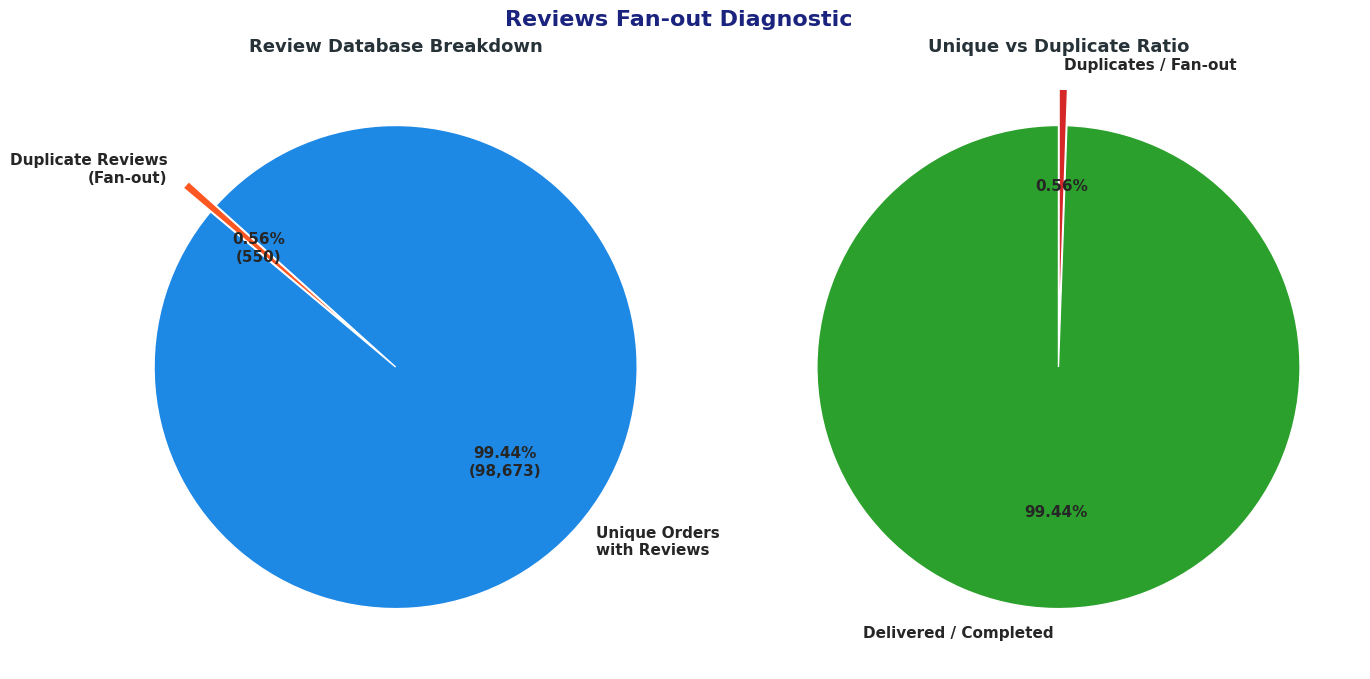

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Connect and fetch the review fan-out metrics
conn = sqlite3.connect(DB_PATH)
query = """
SELECT COUNT(*) AS review_rows, 
       COUNT(DISTINCT order_id) AS distinct_orders,
       COUNT(*) - COUNT(DISTINCT order_id) AS duplicate_rows
FROM order_reviews
"""
df_fanout = pd.read_sql_query(query, conn)
conn.close()

total_reviews = df_fanout.loc[0, 'review_rows']
distinct_orders = df_fanout.loc[0, 'distinct_orders']
duplicate_rows = df_fanout.loc[0, 'duplicate_rows']

# Plotting two side-by-side pie charts
sns.set_theme(style="white")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))

# Chart 1: Absolute Total Breakdown (Unique Orders vs. Duplicate Rows)
labels1 = ['Unique Orders\nwith Reviews', 'Duplicate Reviews\n(Fan-out)']
sizes1 = [distinct_orders, duplicate_rows]
colors1 = ['#1e88e5', '#ff5722']

ax1.pie(
    sizes1,
    labels=labels1,
    autopct=lambda pct: f"{pct:.2f}%\n({int(pct/100.*total_reviews):,})",
    colors=colors1,
    startangle=140,
    explode=(0, 0.15) if duplicate_rows > 0 else (0, 0),
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
ax1.set_title('Review Database Breakdown', fontsize=13, fontweight='bold', pad=10, color='#263238')

# Chart 2: Proportion Focus (Visualizing the 100% composition of total reviews)
labels2 = ['Delivered / Completed', 'Duplicates / Fan-out']
sizes2 = [distinct_orders, duplicate_rows]
colors2 = ['#2ca02c', '#d62728']

ax2.pie(
    sizes2,
    labels=labels2,
    autopct='%1.2f%%',
    colors=colors2,
    startangle=90,
    explode=(0, 0.15) if duplicate_rows > 0 else (0, 0),
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
ax2.set_title('Unique vs Duplicate Ratio', fontsize=13, fontweight='bold', pad=10, color='#263238')

plt.suptitle('Reviews Fan-out Diagnostic', fontsize=16, fontweight='bold', y=0.98, color='#1a237e')
plt.tight_layout()
plt.show()

**Q11. Distinct customers vs customer rows**

Data quality · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard

In [34]:
%%sql
SELECT (SELECT COUNT(*) FROM customers) AS customer_rows,
       (SELECT COUNT(DISTINCT customer_unique_id) FROM customers) AS unique_customers

,customer_rows,unique_customers
0,99441,96096


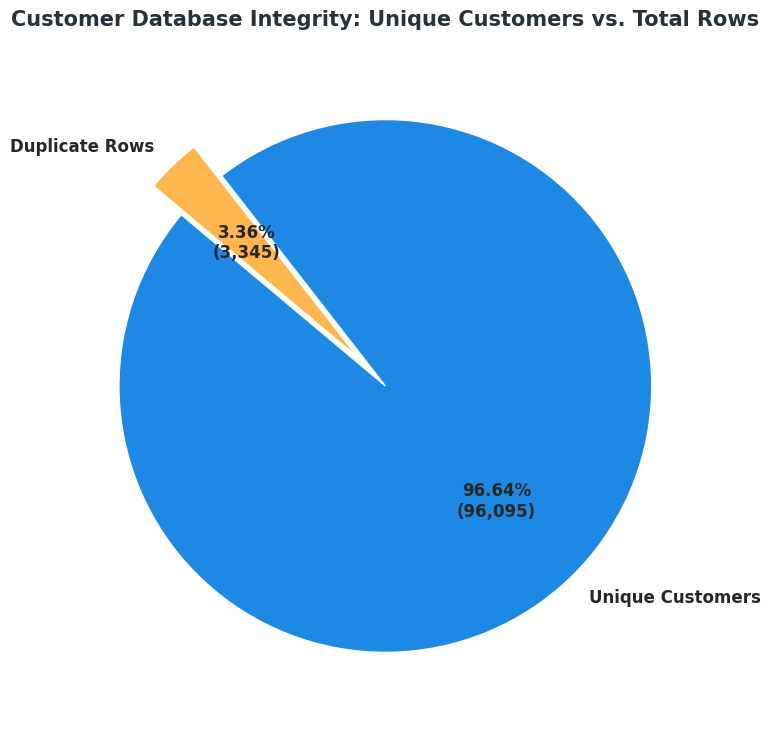

In [37]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Connect and fetch customer metrics
conn = sqlite3.connect(DB_PATH)
query = """
SELECT (SELECT COUNT(*) FROM customers) AS customer_rows,
       (SELECT COUNT(DISTINCT customer_unique_id) FROM customers) AS unique_customers
"""
df_customers = pd.read_sql_query(query, conn)
conn.close()

total_rows = df_customers.loc[0, 'customer_rows']
unique_cust = df_customers.loc[0, 'unique_customers']
duplicate_rows = total_rows - unique_cust

# Setup data for the pie chart
labels = ['Unique Customers', 'Duplicate Rows']
sizes = [unique_cust, duplicate_rows]
colors = ['#1e88e5', '#ffb74d']

plt.figure(figsize=(8, 8))
plt.pie(
    sizes,
    labels=labels,
    autopct=lambda pct: f"{pct:.2f}%\n({int(pct/100.*total_rows):,})" if pct > 0 else '',
    colors=colors,
    startangle=140,
    explode=(0, 0.15) if duplicate_rows > 0 else (0, 0),
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)

plt.title('Customer Database Integrity: Unique Customers vs. Total Rows', fontsize=15, fontweight='bold', pad=20, color='#263238')
plt.tight_layout()
plt.show()

**Q12. Lowest-scoring states (min 2,000 orders)**

Insight · filterable — call with multi_params(...); the table below is the All result

In [38]:
%%sql
SELECT c.customer_state AS state,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_reviews r  ON o.order_id  = r.order_id
WHERE (:state_json = '[]' OR c.customer_state IN (SELECT value FROM json_each(:state_json)))
GROUP BY state HAVING orders >= 2000
ORDER BY avg_score ASC LIMIT 10

,state,orders,avg_score
0,BA,3340,3.86
1,RJ,12687,3.87
2,ES,2006,4.04
3,GO,2007,4.04
4,DF,2128,4.06
5,SC,3609,4.07
6,RS,5443,4.13
7,MG,11554,4.14
8,SP,41472,4.17
9,PR,5019,4.18


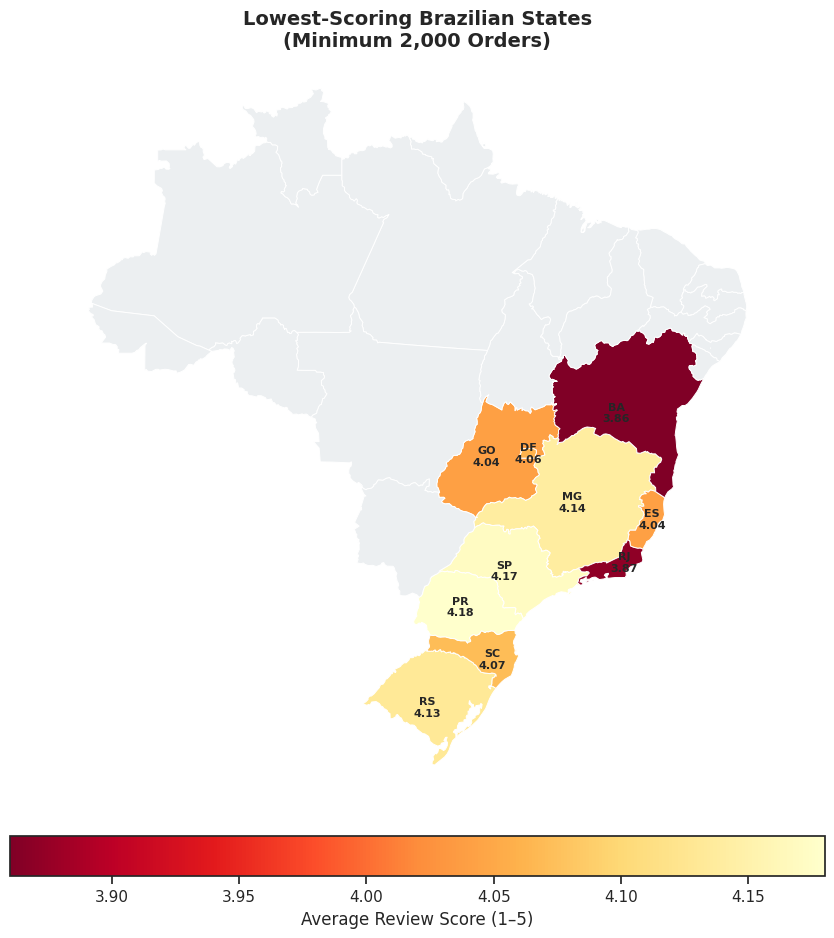

In [45]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

merged_map.plot(
    column="avg_score",
    cmap="YlOrRd_r",
    linewidth=0.7,
    edgecolor="white",
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "#eceff1",
        "edgecolor": "white",
        "label": "Other states"
    },
    legend_kwds={
        "label": "Average Review Score (1–5)",
        "orientation": "horizontal",
        "shrink": 0.7,
        "pad": 0.04
    }
)

for _, row in merged_map.dropna(subset=["avg_score"]).iterrows():
    point = row.geometry.representative_point()

    ax.annotate(
        f"{row['state']}\n{row['avg_score']:.2f}",
        (point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold"
    )

ax.set_title(
    "Lowest-Scoring Brazilian States\n"
    "(Minimum 2,000 Orders)",
    fontsize=14,
    fontweight="bold"
)

ax.set_axis_off()
plt.tight_layout()
plt.show()
